In [18]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [19]:
def get_class_label(class_id):
    binary = f"{class_id+1:06b}"
    return binary[::-1]

## Visualizations on Processed Dataset

In [20]:
character_label_dir = os.listdir("../data/dataset/characters/labels")

all_annots = ""

for split in character_label_dir:
    for label_file in os.listdir(f"../data/dataset/characters/labels/{split}"):
        print(label_file)
        with open(f"../data/dataset/characters/labels/{split}/{label_file}", "r") as f:
            all_annots += f.read()

print(f"Total lines: {len(all_annots)}")


ANG_02.labeled.txt
ANG_0c62b07dc3ff44e4982cbb573f3b6d95.labeled.txt
ANG_0cf2b6ac-036f-429b-8b9d-405415ee5840.labeled.txt
ANG_1-1-771x1024.txt
ANG_1.txt
ANG_12.labeled.txt
ANG_12.txt
ANG_15660462156041370045416.labeled.txt
ANG_16117401078905499179755929287133.labeled.txt
ANG_1613636025206..labeled.txt
ANG_16158293792985296089064141415508.labeled.txt
ANG_16166167545185647725257998309614.labeled.txt
ANG_16176160088617889824558606265568.labeled.txt
ANG_16187743941276670750846468527301.labeled.txt
ANG_16212558309825739935733992080657.labeled.txt
ANG_2378374bda87d842436936f81d442bfb.labeled.txt
ANG_3_8.labeled.txt
ANG_592644964b764e4090a3c8b35ea042c7.labeled.txt
ANG_648bb39e-7f24-461c-9a77-04bed24bbc2e.labeled.txt
ANG_6c4425c1-ecb1-499f-ad8a-283f802a1936.labeled.txt
ANG_d5cbb2a0-8acc-494b-be10-13e0cfc4c09f.labeled.txt
ANG_f19ffeceaa1658.txt
ANG_image017.txt
ANG_image050.txt
ANG_image_1104.labeled.txt
ANG_image_1330.labeled.txt
ANG_image_264.labeled.txt
ANG_image_768.labeled.txt
ANG_IMG_20190

In [21]:
parsed_annots = [list(map(float, a.split())) for a in all_annots.split("\n")]

print(parsed_annots[:5])

[[4.0, 0.09423828125, 0.14825581395348836, 0.0244140625, 0.02906976744186049], [20.0, 0.12451171875, 0.14789244186046513, 0.0244140625, 0.028343023255813976], [29.0, 0.15625, 0.14752906976744184, 0.025390625, 0.02906976744186049], [9.0, 0.1875, 0.14716569767441862, 0.025390625, 0.028343023255813976], [4.0, 0.21923828125, 0.14680232558139536, 0.0244140625, 0.02906976744186046]]


In [22]:
classes = [int(a[0]) for a in parsed_annots if len(a) > 0]
widths = [a[3] for a in parsed_annots if len(a) > 0]
heights = [a[4] for a in parsed_annots if len(a) > 0]

print(max(classes))
print(max(widths))
print(max(heights))

62
0.0341796875
0.05729166666666674


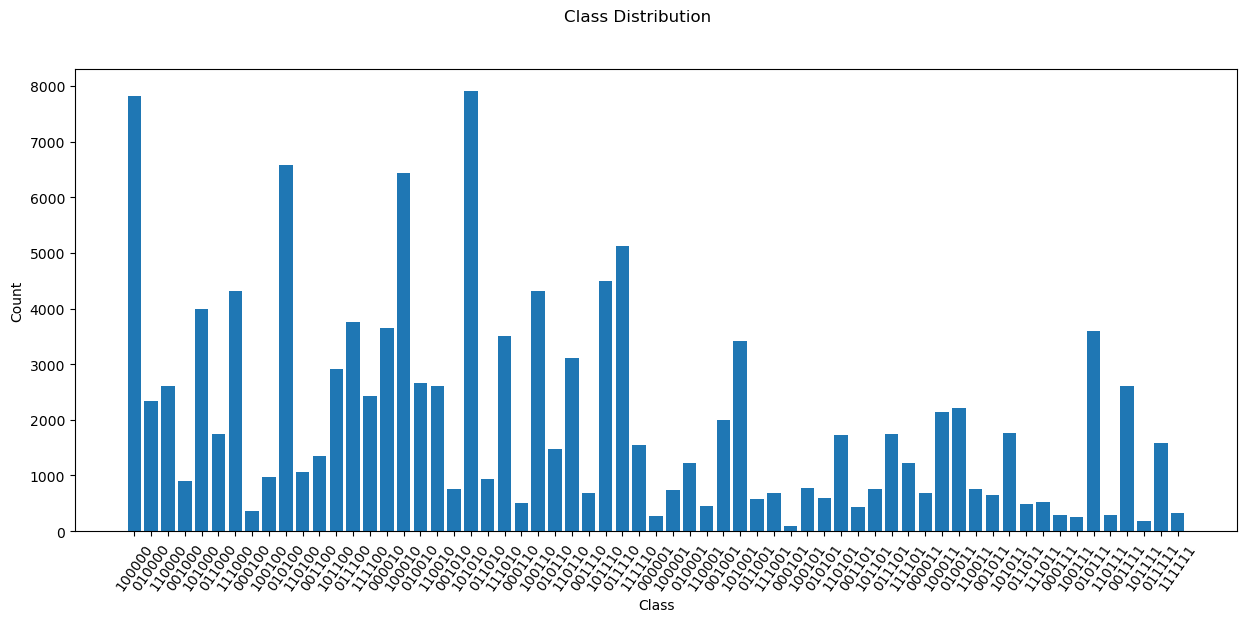

In [23]:
plt.figure(figsize=(15,6))

plt.bar(x=[get_class_label(i) for i in range(0,63)], height=[classes.count(i) for i in range(0,63)])
plt.xticks([get_class_label(i) for i in range(0,63)], rotation=55, size=10)
plt.xlabel("Class")
plt.ylabel("Count")
plt.suptitle("Class Distribution")

plt.savefig("../visualizations/angelina+dsbi_class_label_distribution.png")
plt.show()

## Visualizations on Raw Dataset

In [24]:
IGNORE_DIRS = ['.gitignore', 'pics', 'src', 'README.md', 'train.txt', 'val.txt', 'test.txt', 'figures']
angelina_raw_path = "../data/raw/AngelinaDataset-master"
dsbi_raw_path = "../data/raw/DSBI-master"


In [25]:
# Angelina Annotations Parsing

def parse_angelina_character(label_path):
    parsed_lines=[]
    with open(label_path, 'r') as file:
        for line in file:
            line=line.strip()
            if line:
                x1, y1, x2, y2, c = line.split(';')
                width = (float(x2)) - float(x1)    
                height = float(y2) - float(y1)
                x_c = float(x1) + width / 2
                y_c = float(y1) + height / 2
                c = int(c) - 1

                parsed_lines.append([c, x_c, y_c, width, height])
    
    return parsed_lines

# DSBI Annotations Parsing

def parse_dsbi_character(label_path):
    parsed_lines = []

    with open(label_path, 'r') as file:
        lines = file.readlines()

    if len(lines) <= 3:
        return parsed_lines

    v_lines = [int(x) for x in lines[1].strip().split()]
    h_lines = [int(x) for x in lines[2].strip().split()] 

    for i in range(3, len(lines)):
        parts = lines[i].strip().split()
        if len(parts) < 8:
            continue

        row = int(parts[0])
        col = int(parts[1])

        try:
            x1 = v_lines[2*(col-1)]
            x2 = v_lines[2*(col-1)+1]

            y1 = h_lines[3*(row-1)]
            y2 = h_lines[3*(row-1)+2]
        except IndexError:
            continue

        dots = ''.join(parts[2:][::-1])
        c = int(dots, 2)

        # Skip if the cell is empty (annot == 000000)
        if c == 0:
            continue

        c = c - 1 # convert to 0-based index
        width = x2 - x1
        height = y2 - y1


        x_c = x1 + width / 2
        y_c = y1 + height / 2

        width += 0.8 * width # add 80% of the grid width
        height += 0.5 * height # add 50% of the grid height
        
        parsed_lines.append([c, x_c, y_c, width, height])

    return parsed_lines  

In [26]:
angelina_annots = []

for category in os.listdir(angelina_raw_path):
    if category in IGNORE_DIRS:
        continue

    category_path = os.path.join(angelina_raw_path, category)

    for folder in os.listdir(category_path):
        if folder in IGNORE_DIRS:
            continue
        for label_file in os.listdir(os.path.join(category_path, folder)):
            if label_file.endswith('.csv'):
                label_path = os.path.join(category_path, folder, label_file)
                parsed_lines = parse_angelina_character(label_path)
                angelina_annots.extend(parsed_lines)

print("Angelina Parsed [:5]:", angelina_annots[:5])

ang_classes = [a[0] for a in angelina_annots if len(a) > 0]
ang_widths = [a[3] for a in angelina_annots]
ang_heights = [a[4] for a in angelina_annots]

print("Angelina Classes [:5]:", ang_classes[:5])
print("Angelina Widths [:5]:", ang_widths[:5])
print("Angelina Heights [:5]:", ang_heights[:5])

Angelina Parsed [:5]: [[4, 0.2919921875, 0.07739825581395349, 0.02734375, 0.03125], [49, 0.3271484375, 0.07630813953488372, 0.02734375, 0.031976744186046506], [9, 0.361328125, 0.07521802325581395, 0.02734375, 0.031249999999999993], [49, 0.3974609375, 0.07521802325581395, 0.02734375, 0.031249999999999993], [30, 0.466796875, 0.07303779069767442, 0.02734375, 0.03125000000000001]]
Angelina Classes [:5]: [4, 49, 9, 49, 30]
Angelina Widths [:5]: [0.02734375, 0.02734375, 0.02734375, 0.02734375, 0.02734375]
Angelina Heights [:5]: [0.03125, 0.031976744186046506, 0.031249999999999993, 0.031249999999999993, 0.03125000000000001]


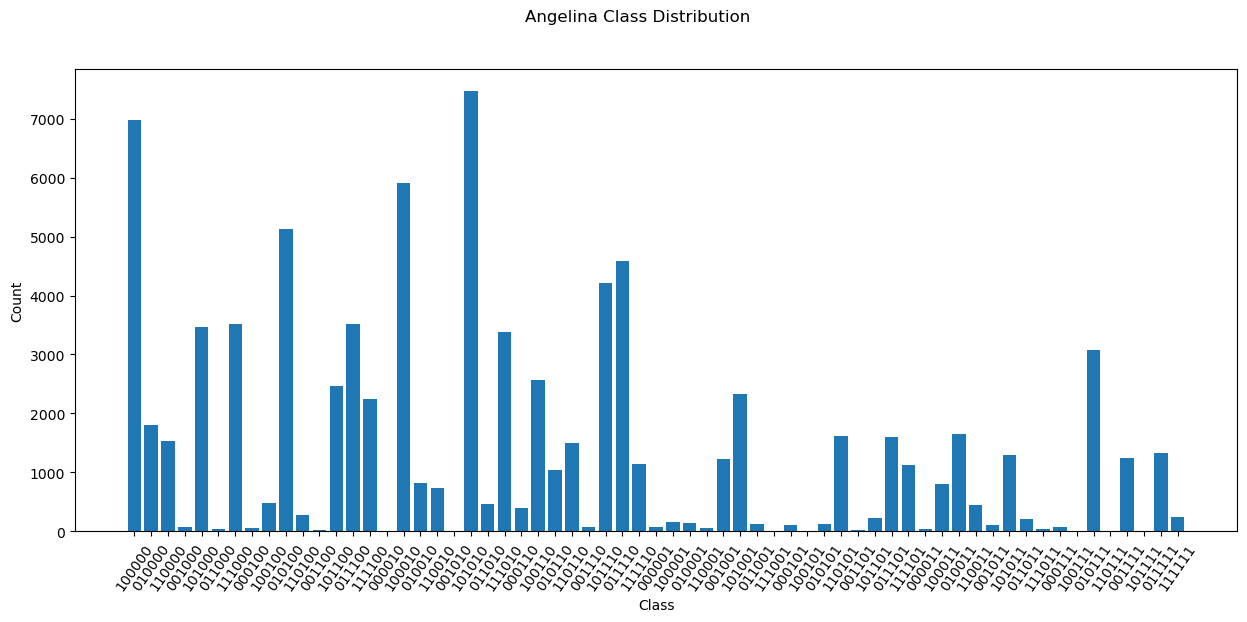

In [27]:
plt.figure(figsize=(15,6))

plt.bar(x=[get_class_label(i) for i in range(0,63)], height=[ang_classes.count(i) for i in range(0,63)])
plt.xticks([get_class_label(i) for i in range(0,63)], rotation=55, size=10)
plt.xlabel("Class")
plt.ylabel("Count")
plt.suptitle("Angelina Class Distribution")

plt.savefig("../visualizations/angelina_class_label_distribution.png")
plt.show()

In [28]:
dsbi_annots = []

for category in os.listdir(dsbi_raw_path):
    if category in IGNORE_DIRS:
        continue

    category_path = os.path.join(dsbi_raw_path, category)

    for folder in os.listdir(category_path):
        if folder in IGNORE_DIRS:
            continue
        for label_file in os.listdir(os.path.join(category_path, folder)):
            if label_file.endswith('+recto.txt'):
                label_path = os.path.join(category_path, folder, label_file)
                parsed_lines = parse_dsbi_character(label_path)
                dsbi_annots.extend(parsed_lines)

print("DSBI Parsed [:5]:", dsbi_annots[:5])

dsbi_classes = [a[0] for a in dsbi_annots if len(a) > 0]
dsbi_widths = [a[3] for a in dsbi_annots]
dsbi_heights = [a[4] for a in dsbi_annots]

print("DSBI Classes [:5]:", dsbi_classes[:5])
print("DSBI Widths [:5]:", dsbi_widths[:5])
print("DSBI Heights [:5]:", dsbi_heights[:5])

DSBI Parsed [:5]: [[4, 296.0, 302.0, 43.2, 63.0], [38, 348.5, 302.0, 45.0, 63.0], [26, 399.5, 302.0, 37.8, 63.0], [20, 451.0, 302.0, 39.6, 63.0], [12, 555.0, 302.0, 39.6, 63.0]]
DSBI Classes [:5]: [4, 38, 26, 20, 12]
DSBI Widths [:5]: [43.2, 45.0, 37.8, 39.6, 39.6]
DSBI Heights [:5]: [63.0, 63.0, 63.0, 63.0, 63.0]


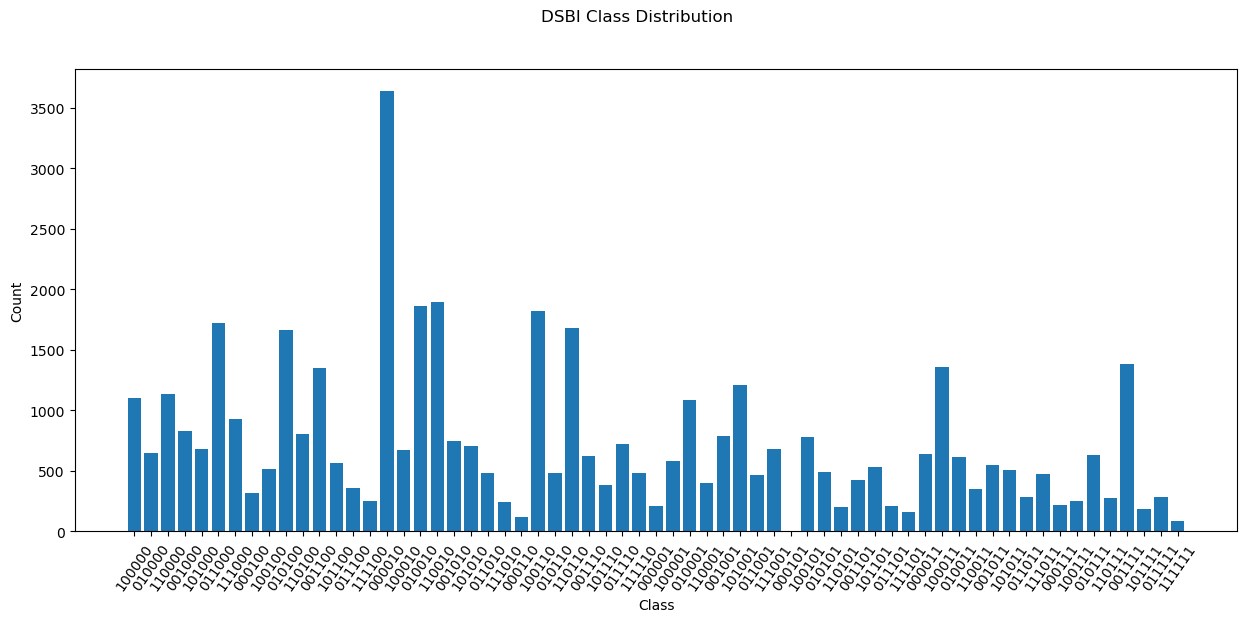

In [29]:
plt.figure(figsize=(15,6))

plt.bar(x=[get_class_label(i) for i in range(0,63)], height=[dsbi_classes.count(i) for i in range(0,63)])
plt.xticks([get_class_label(i) for i in range(0,63)], rotation=55, size=10)
plt.xlabel("Class")
plt.ylabel("Count")
plt.suptitle("DSBI Class Distribution")

plt.savefig("../visualizations/dsbi_class_label_distribution.png")
plt.show()